# Оценка кредитоспособности заёмщиков: логистическая регрессия

**Задача.** По характеристикам заёмщика и ссуды оценить вероятность того, что ссуда
не будет выплачена (`default`), и классифицировать заявки на «рискованные» и «надёжные».

**Данные.** Подготовленная выборка ссуд американской P2P-платформы Lending Club.
- `loan_data.csv.gz` — 45 342 ссуды, где невыплат и погашений ровно поровну;
- `full_train_set.csv.gz` — 119 987 ссуд с естественной долей невыплат (~19%);
- `loan3000.csv` — выборка из 3 000 ссуд для наглядного сравнения моделей.

**План.**
1. Данные.
2. Логит и шансы: как логистическая регрессия превращает вероятность в линейную модель.
3. Логистическая регрессия: коэффициенты, отношения шансов, предсказанные вероятности.
4. GLM в statsmodels: значимость коэффициентов, сплайны, частные остатки.
5. Оценка качества: матрица ошибок, precision, recall, specificity, ROC-кривая, AUC.
6. Несбалансированные данные: понижающий отбор, перевзвешивание, SMOTE и ADASYN.
7. Сравнение границ решений: LDA, логистическая регрессия, GAM.
8. Расширенная модель: 8 новых признаков и оценка на отложенной выборке.
9. Итоги.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from cycler import cycler
from imblearn.over_sampling import ADASYN, SMOTE
from pygam import LogisticGAM, s
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import OrdinalEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

LOAN3000_CSV = DATA / "loan3000.csv"
LOAN_DATA_CSV = DATA / "loan_data.csv.gz"
FULL_TRAIN_SET_CSV = DATA / "full_train_set.csv.gz"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# pyGAM выдаёт RuntimeWarning при вероятностях, близких к 0 или 1; на результат не влияет
warnings.filterwarnings("ignore", category=RuntimeWarning, module="pygam")

# Стиль графиков
PAL = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
       "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9",
       "axis": "#c3c2b7", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"], "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": PAL["axis"], "axes.labelcolor": PAL["ink2"], "text.color": PAL["ink"],
    "xtick.color": PAL["muted"], "ytick.color": PAL["muted"],
    "axes.grid": True, "grid.color": PAL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.prop_cycle": cycler(color=[PAL["blue"], PAL["orange"], PAL["aqua"], PAL["yellow"]]),
    "lines.linewidth": 2, "legend.frameon": False,
})


def save(fig, name):
    """Сохраняет график в reports/figures и выводит его."""
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Данные

Каждая строка — одна ссуда. Целевая переменная `outcome`: `default` (не выплачена)
или `paid off` (погашена). Признаки базовой модели:

| Признак | Описание |
|---|---|
| `payment_inc_ratio` | отношение ежемесячного платежа по ссуде к доходу заёмщика, % |
| `purpose_` | цель ссуды: кредитная карта, рефинансирование долгов, ремонт, крупная покупка, медицина, малый бизнес, другое |
| `home_` | жильё: ипотека (`MORTGAGE`), собственное (`OWN`), аренда (`RENT`) |
| `emp_len_` | стаж на текущей работе: меньше или больше года |
| `borrower_score` | балл кредитоспособности заёмщика из датасета: от 0 (низкая) до 1 (высокая) |

В `loan_data` невыплаты и погашения представлены поровну (выборка сбалансирована
понижающим отбором). Модель при естественной доле невыплат рассматривается в разделе 6
на `full_train_set`.

In [2]:
loan_data = pd.read_csv(LOAN_DATA_CSV)

# категориальные переменные; порядок классов: сначала "paid off", потом "default"
loan_data.outcome = loan_data.outcome.astype("category")
loan_data.outcome = loan_data.outcome.cat.reorder_categories(["paid off", "default"])
loan_data.purpose_ = loan_data.purpose_.astype("category")
loan_data.home_ = loan_data.home_.astype("category")
loan_data.emp_len_ = loan_data.emp_len_.astype("category")

print("Размер:", loan_data.shape)
print(loan_data["outcome"].value_counts())
loan_data[["outcome", "payment_inc_ratio", "purpose_", "home_", "emp_len_", "borrower_score"]].head()

Размер: (45342, 21)
outcome
paid off    22671
default     22671
Name: count, dtype: int64


,outcome,payment_inc_ratio,purpose_,home_,emp_len_,borrower_score
0,default,2.39320,major_purchase,RENT,> 1 Year,0.65
1,default,4.57170,small_business,OWN,> 1 Year,0.80
2,default,9.71600,other,RENT,> 1 Year,0.60
3,default,12.21520,debt_consolidation,RENT,> 1 Year,0.50
4,default,3.90888,other,RENT,> 1 Year,0.55


In [3]:
loan_data[["payment_inc_ratio", "borrower_score"]].describe().round(3)

,payment_inc_ratio,borrower_score
count,45342.000,45342.000
mean,8.032,0.499
std,4.264,0.129
min,0.049,0.050
25%,4.672,0.400
50%,7.499,0.500
75%,10.941,0.600
max,43.546,1.000


In [4]:
# Доля невыплат по категориям
for col in ["purpose_", "home_", "emp_len_"]:
    t = (loan_data.groupby(col, observed=True)["outcome"]
         .apply(lambda x: (x == "default").mean()).rename("доля default"))
    print(pd.concat([loan_data[col].value_counts().rename("ссуд"), t.round(3)], axis=1), "\n")

                     ссуд  доля default
purpose_                               
debt_consolidation  25570         0.510
credit_card          7688         0.447
other                4886         0.536
home_improvement     2977         0.455
major_purchase       2060         0.410
small_business       1513         0.685
medical               648         0.502 

           ссуд  доля default
home_                        
MORTGAGE  20876         0.468
RENT      20744         0.530
OWN        3722         0.507 

           ссуд  доля default
emp_len_                     
> 1 Year  43566         0.496
< 1 Year   1776         0.604 



## 2. Логит и шансы

Логистическая регрессия моделирует не вероятность невыплаты p, а логарифм шансов
(логит). Логит принимает значения от −∞ до +∞ и поэтому может быть линейной функцией
признаков:

log(p / (1 − p)) = β₀ + β₁x₁ + … + βₖxₖ

Вероятность восстанавливается логистической функцией: p = 1 / (1 + e^−(β₀ + β₁x₁ + …)).

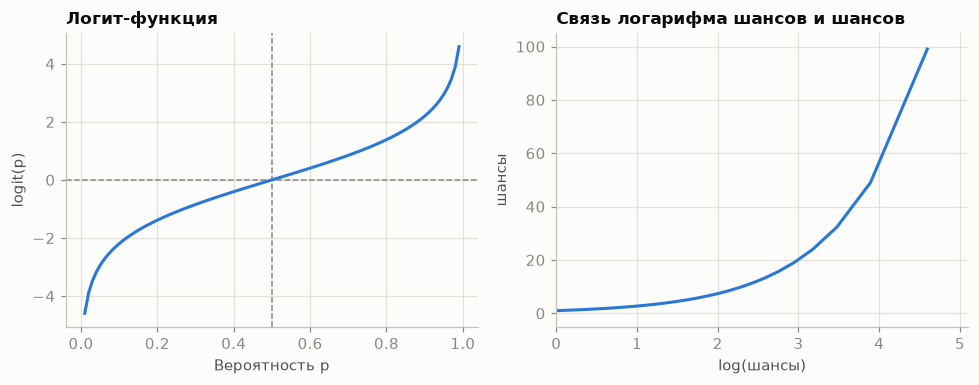

In [5]:
p = np.arange(0.01, 1, 0.01)
df = pd.DataFrame({
    "p": p,
    "logit": np.log(p / (1 - p)),
    "odds": p / (1 - p),
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6))
ax1.axhline(0, color=PAL["muted"], linestyle="--", lw=1)
ax1.axvline(0.5, color=PAL["muted"], linestyle="--", lw=1)
ax1.plot(df["p"], df["logit"])
ax1.set_xlabel("Вероятность p")
ax1.set_ylabel("logit(p)")
ax1.set_title("Логит-функция")

ax2.plot(df["logit"], df["odds"])
ax2.set_xlabel("log(шансы)")
ax2.set_ylabel("шансы")
ax2.set_xlim(0, 5.1)
ax2.set_ylim(-5, 105)
ax2.set_title("Связь логарифма шансов и шансов")
fig.tight_layout()
save(fig, "01_logit_odds")

Слева: логит равен 0 при p = 0.5 и стремится к ±∞ при p → 0 и p → 1. Справа: коэффициенты
модели измеряются на шкале логарифма шансов, и рост коэффициента на 1 соответствует
умножению шансов в e ≈ 2.72 раза.

## 3. Логистическая регрессия

### 3.1 Подгонка в scikit-learn

Категориальные признаки закодированы фиктивными переменными (`get_dummies`,
`drop_first=True`). Опорные уровни: `credit_card` (цель), `MORTGAGE` (жильё), `< 1 Year`
(стаж); коэффициенты остальных уровней отражают разницу с опорным. Регуляризация,
включённая в scikit-learn по умолчанию, отключена очень большим значением `C`.

In [6]:
predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_", "borrower_score"]
outcome = "outcome"
X = pd.get_dummies(loan_data[predictors], prefix="", prefix_sep="",
                   drop_first=True, dtype=int)
y = loan_data[outcome]

logit_reg = LogisticRegression(C=1e42, solver="liblinear")
logit_reg.fit(X, y)

print("intercept ", logit_reg.intercept_[0])
print("classes", logit_reg.classes_)
pd.DataFrame({"coeff": logit_reg.coef_[0]}, index=X.columns)

intercept  -1.6378907921853014
classes ['default' 'paid off']


,coeff
payment_inc_ratio,-0.079739
borrower_score,4.612183
debt_consolidation,-0.249414
home_improvement,-0.407734
major_purchase,-0.229710
medical,-0.510744
other,-0.620800
small_business,-1.214936
OWN,-0.048211
RENT,-0.157288


In [7]:
print(loan_data["purpose_"].cat.categories)
print(loan_data["home_"].cat.categories)
print(loan_data["emp_len_"].cat.categories)

Index(['credit_card', 'debt_consolidation', 'home_improvement', 'major_purchase', 'medical', 'other', 'small_business'], dtype='str')
Index(['MORTGAGE', 'OWN', 'RENT'], dtype='str')
Index([' < 1 Year', ' > 1 Year'], dtype='str')


scikit-learn упорядочивает классы по алфавиту (`['default', 'paid off']`), поэтому
положительным классом становится `paid off`, и коэффициенты выше описывают шансы
погашения. Для интерпретации в терминах невыплаты целевая переменная кодируется явно:
`paid off` → 0, `default` → 1.

In [8]:
enc = OrdinalEncoder(categories=[["paid off", "default"]])
y_enc = enc.fit_transform(loan_data[[outcome]]).ravel()

logit_reg_enc = LogisticRegression(C=1e42, solver="liblinear")
logit_reg_enc.fit(X, y_enc)

print("intercept ", logit_reg_enc.intercept_[0])
print("classes", logit_reg_enc.classes_)
coefs = pd.DataFrame({"coeff": logit_reg_enc.coef_[0]}, index=X.columns)
coefs["odds_ratio"] = np.exp(coefs["coeff"])
coefs.round(4)

intercept  1.637890823185279
classes [0. 1.]


,coeff,odds_ratio
payment_inc_ratio,0.0797,1.0830
borrower_score,-4.6122,0.0099
debt_consolidation,0.2494,1.2833
home_improvement,0.4077,1.5034
major_purchase,0.2297,1.2582
medical,0.5107,1.6665
other,0.6208,1.8604
small_business,1.2149,3.3701
OWN,0.0482,1.0494
RENT,0.1573,1.1703


### 3.2 Отношения шансов

Отношение шансов e^β — множитель шансов невыплаты при росте признака на единицу или при
переходе от опорной категории к данной.

- **Цель ссуды.** Шансы невыплаты по ссудам малому бизнесу примерно в 3.4 раза выше, чем
  по ссудам на погашение кредитной карты; остальные цели также рискованнее опорной.
- **Отношение платежа к доходу.** +1 п.п. увеличивает шансы невыплаты примерно в 1.08 раза.
- **Аренда жилья** повышает шансы невыплаты относительно ипотеки; собственное жильё от
  ипотеки практически не отличается.
- **Стаж больше года** снижает шансы невыплаты.
- **Балл кредитоспособности** — самый сильный признак: коэффициент около −4.6 означает,
  что шансы невыплаты при балле 1 примерно в 100 раз ниже, чем при балле 0 (e^−4.6 ≈ 0.01).

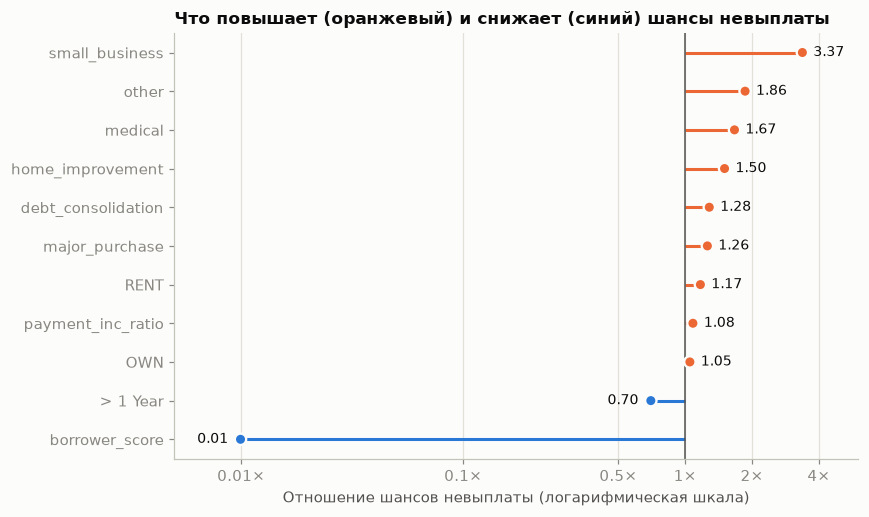

In [9]:
or_plot = coefs.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 4.8))
colors = [PAL["orange"] if v > 1 else PAL["blue"] for v in or_plot["odds_ratio"]]
ypos = np.arange(len(or_plot))
# отрезок от 1× (нет эффекта) до отношения шансов
ax.hlines(ypos, 1, or_plot["odds_ratio"], color=colors, lw=2)
ax.scatter(or_plot["odds_ratio"], ypos, color=colors, s=55, zorder=3,
           edgecolor=PAL["surface"], lw=1.5)
ax.axvline(1, color=PAL["ink2"], lw=1)
ax.set_xscale("log")
ax.set_xlim(0.005, 6)
ax.set_xticks([0.01, 0.1, 0.5, 1, 2, 4])
ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_yticks(ypos, or_plot.index.str.strip())
for yv, v in zip(ypos, or_plot["odds_ratio"]):
    ax.text(v * (1.12 if v > 1 else 0.88), yv, f"{v:.2f}", va="center",
            ha="left" if v > 1 else "right", fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Отношение шансов невыплаты (логарифмическая шкала)")
ax.set_title("Что повышает (оранжевый) и снижает (синий) шансы невыплаты")
fig.tight_layout()
save(fig, "02_odds_ratios")

### 3.3 Предсказанные значения

`predict_log_proba` возвращает логарифмы вероятностей, `predict_proba` — вероятности
в порядке `logit_reg.classes_` (`default`, `paid off`).

In [10]:
pred = pd.DataFrame(logit_reg.predict_log_proba(X), columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean      -0.757872     -0.760434
std        0.378093      0.390456
min       -2.769376     -3.538593
25%       -0.985739     -0.977207
50%       -0.697406     -0.688907
75%       -0.472183     -0.467069
max       -0.029485     -0.064753


In [11]:
pred = pd.DataFrame(logit_reg.predict_proba(X), columns=logit_reg.classes_)
print(pred.describe())

            default      paid off
count  45342.000000  45342.000000
mean       0.500000      0.500000
std        0.167354      0.167354
min        0.062701      0.029054
25%        0.373163      0.376361
50%        0.497875      0.502125
75%        0.623639      0.626837
max        0.970946      0.937299


Вероятности невыплаты лежат в диапазоне ~0.06–0.97, медиана около 0.5. Решение об
одобрении требует порога отсечения (например, 0.5); выбор порога рассматривается
в разделе 5.

## 4. GLM в statsmodels

Логистическая регрессия — частный случай обобщённой линейной модели (GLM)
с биномиальным распределением и логит-связью. statsmodels дополнительно выдаёт
стандартные ошибки, z-статистики, p-значения и доверительные интервалы коэффициентов.

In [12]:
# GLM с биномиальным семейством = логистическая регрессия
y_numbers = [1 if yi == "default" else 0 for yi in y]
logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
print(logit_result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Fri, 06 Nov 2026   Deviance:                       57515.
Time:                        21:17:04   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0

Коэффициенты совпадают с моделью scikit-learn для `default` = 1. Все признаки, кроме
`OWN` (p ≈ 0.2), значимы. R² и RMSE для логистической регрессии не определены, поэтому
качество оценивается метриками классификации (раздел 5). Девиация (deviance) — мера
расхождения модели с данными при оценке методом максимального правдоподобия.

### 4.1 Сплайны

B-сплайны (`bs(...)`) позволяют учесть нелинейную связь `payment_inc_ratio`
и `borrower_score` с логитом.

In [13]:
formula = ("outcome ~ bs(payment_inc_ratio, df=8) + purpose_ + "
           "home_ + emp_len_ + bs(borrower_score, df=3)")
model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()
print(results.summary())

                             Generalized Linear Model Regression Results                             
Dep. Variable:     ['outcome[paid off]', 'outcome[default]']   No. Observations:                45342
Model:                                                   GLM   Df Residuals:                    45321
Model Family:                                       Binomial   Df Model:                           20
Link Function:                                         Logit   Scale:                          1.0000
Method:                                                 IRLS   Log-Likelihood:                -28731.
Date:                                       Fri, 06 Nov 2026   Deviance:                       57462.
Time:                                               21:17:05   Pearson chi2:                 4.54e+04
No. Iterations:                                            6   Pseudo R-squ. (CS):             0.1122
Covariance Type:                                   nonrobust                      

Целевая переменная передана как категория с уровнями `paid off`, `default`, поэтому
statsmodels моделирует вероятность первого уровня — погашения, и знаки коэффициентов
противоположны модели для `default`.

### 4.2 Частные остатки

График частных остатков показывает вклад одного признака (линия) на фоне остатков модели
(точки). Из-за бинарного исхода остатки образуют два облака, по одному на класс. График
используется для проверки нелинейности и поиска влиятельных наблюдений.

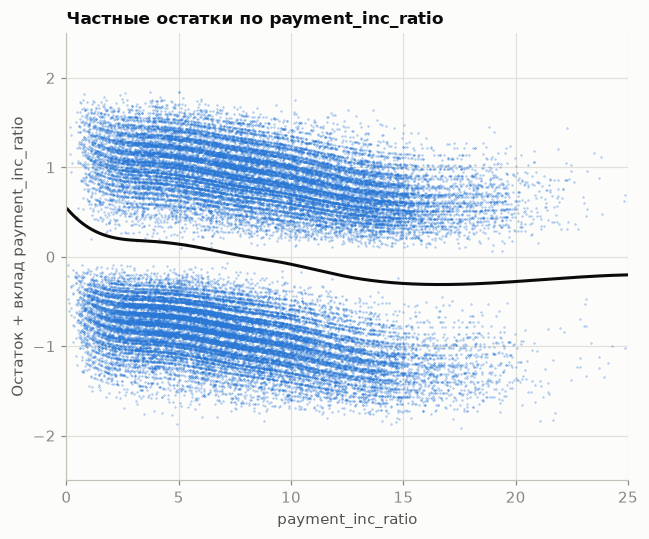

In [14]:
def partialResidualPlot(model, df, outcome, feature, fig, ax):
    y_actual = [0 if s == "default" else 1 for s in df[outcome]]
    y_pred = model.predict(df)
    org_params = model.params.copy()
    zero_params = model.params.copy()
    # обнуляем параметры всех признаков, кроме выбранного
    for i, name in enumerate(zero_params.index):
        if feature in name:
            continue
        zero_params.iloc[i] = 0.0
    model.initialize(model.model, zero_params)
    feature_prediction = model.predict(df)
    ypartial = -np.log(1 / feature_prediction - 1)
    ypartial = ypartial - np.mean(ypartial)
    model.initialize(model.model, org_params)
    results = pd.DataFrame({
        "feature": df[feature],
        "residual": -2 * (y_actual - y_pred),
        "ypartial": ypartial / 2,
    })
    results = results.sort_values(by=["feature"])

    ax.scatter(results.feature, results.residual, marker=".", s=72. / fig.dpi,
               color=PAL["blue"], alpha=0.5)
    ax.plot(results.feature, results.ypartial, color=PAL["ink"])
    ax.set_xlabel(feature)
    ax.set_ylabel(f"Остаток + вклад {feature}")
    return ax


fig, ax = plt.subplots(figsize=(6, 5))
partialResidualPlot(results, loan_data, "outcome", "payment_inc_ratio", fig, ax)
ax.set_xlim(0, 25)
ax.set_ylim(-2.5, 2.5)
ax.set_title("Частные остатки по payment_inc_ratio")
fig.tight_layout()
save(fig, "03_partial_residuals")

Модель описывает шансы погашения, поэтому линия убывает: с ростом доли платежа в доходе
шансы погашения снижаются. Спад неравномерный — наиболее крутой примерно до 2.5%,
плавный до ~15%, далее плато, где данных мало. Связь с логитом нелинейна.

## 5. Оценка качества классификации

Оценивается модель `logit_reg` (scikit-learn, без сплайнов) при пороге 0.5. Метрики
разделов 5–7 посчитаны на обучающих данных; оценка на отложенной выборке — в разделе 8.

### 5.1 Матрица ошибок

In [15]:
pred = logit_reg.predict(X)
pred_y = logit_reg.predict(X) == "default"
true_y = y == "default"
true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame([[np.sum(true_pos), np.sum(false_neg)],
                         [np.sum(false_pos), np.sum(true_neg)]],
                        index=["Y = default", "Y = paid off"],
                        columns=["Yhat = default", "Yhat = paid off"])
print(conf_mat)

              Yhat = default  Yhat = paid off
Y = default            14337             8334
Y = paid off            8149            14522


In [16]:
print(confusion_matrix(y, logit_reg.predict(X)))

[[14337  8334]
 [ 8149 14522]]


In [17]:
def classification_summary(y_true, y_pred, class_names):
    """Матрица ошибок и accuracy."""
    cm = confusion_matrix(y_true, y_pred, labels=class_names)
    print(f"Матрица ошибок (accuracy = {accuracy_score(y_true, y_pred):.4f})\n")
    print(pd.DataFrame(cm, index=[f"факт: {c}" for c in class_names],
                       columns=[f"прогноз: {c}" for c in class_names]))


classification_summary(y, logit_reg.predict(X), class_names=logit_reg.classes_)

Матрица ошибок (accuracy = 0.6365)

                прогноз: default  прогноз: paid off
факт: default              14337               8334
факт: paid off              8149              14522


### 5.2 Precision, recall, specificity

Положительный класс — `default`:
- **precision** — доля действительно невыплаченных среди ссуд, отмеченных как невыплата;
- **recall** (чувствительность) — доля найденных невыплат среди всех невыплат;
- **specificity** (специфичность) — доля верно распознанных погашенных ссуд.

In [18]:
conf_mat = confusion_matrix(y, logit_reg.predict(X))
precision = conf_mat[0, 0] / sum(conf_mat[:, 0])
recall = conf_mat[0, 0] / sum(conf_mat[0, :])
specificity = conf_mat[1, 1] / sum(conf_mat[1, :])
print("Precision  ", round(precision, 4))
print("Recall     ", round(recall, 4))
print("Specificity", round(specificity, 4))

Precision   0.6376
Recall      0.6324
Specificity 0.6406


In [19]:
precision_recall_fscore_support(y, logit_reg.predict(X), labels=["default", "paid off"])

(array([0.63759673, 0.63536927]),
 array([0.63239381, 0.64055401]),
 array([0.63498461, 0.63795111]),
 array([22671, 22671]))

### 5.3 ROC-кривая и AUC

ROC-кривая показывает компромисс между recall и specificity при всех порогах. AUC —
вероятность того, что случайная невыплаченная ссуда получит более высокий скор, чем
случайная погашенная: 0.5 соответствует случайному угадыванию, 1.0 — идеальной модели.

AUC (вручную, по формуле площади): 0.6917
AUC (roc_auc_score):               0.6917


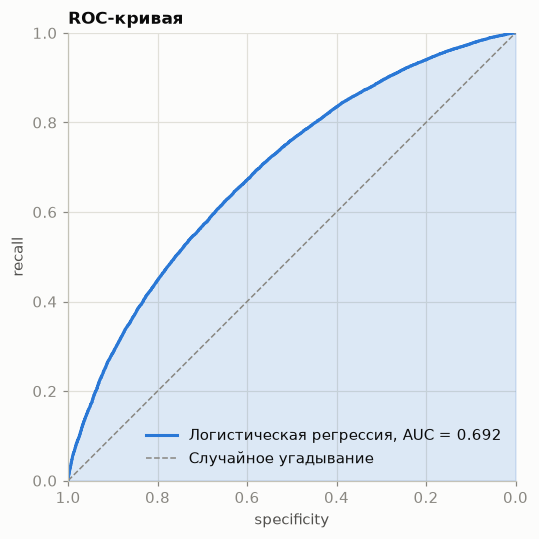

In [20]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0], pos_label="default")
roc_df = pd.DataFrame({"recall": tpr, "specificity": 1 - fpr})

auc_manual = np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity))
auc = roc_auc_score([1 if yi == "default" else 0 for yi in y], logit_reg.predict_proba(X)[:, 0])
print("AUC (вручную, по формуле площади):", round(auc_manual, 4))
print("AUC (roc_auc_score):              ", round(auc, 4))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(roc_df.specificity, roc_df.recall, label=f"Логистическая регрессия, AUC = {auc:.3f}")
ax.fill_between(roc_df.specificity, 0, roc_df.recall, alpha=0.15, color=PAL["blue"])
ax.plot((1, 0), (0, 1), color=PAL["muted"], lw=1, ls="--", label="Случайное угадывание")
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.set_xlabel("specificity")
ax.set_ylabel("recall")
ax.set_title("ROC-кривая")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "04_roc")

Ось specificity развёрнута от 1 к 0, что эквивалентно стандартным координатам FPR–TPR
(specificity = 1 − FPR).

Порог определяется стоимостью ошибок. Пропуск невыплаты (false negative) обычно дороже
ошибочного отказа (false positive), поэтому порог ниже 0.5 может быть выгоднее: recall
растёт за счёт большего числа отказов.

In [21]:
# Как метрики меняются при разных порогах вероятности невыплаты
p_default = logit_reg.predict_proba(X)[:, 0]
rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flag = p_default >= thr
    tp, fp = (flag & true_y).sum(), (flag & ~true_y).sum()
    fn, tn = (~flag & true_y).sum(), (~flag & ~true_y).sum()
    rows.append({"порог": thr, "доля отказов": flag.mean(), "precision": tp / (tp + fp),
                 "recall": tp / (tp + fn), "specificity": tn / (tn + fp)})
thresholds_table = pd.DataFrame(rows)
thresholds_table.round(3)

,порог,доля отказов,precision,recall,specificity
0,0.3,0.871,0.540,0.940,0.199
1,0.4,0.700,0.586,0.820,0.420
2,0.5,0.496,0.638,0.632,0.641
3,0.6,0.294,0.703,0.413,0.825
4,0.7,0.132,0.763,0.201,0.937


## 6. Несбалансированные данные

В `full_train_set` невыплаты составляют около 19%. Модель, обученная на таких данных
без коррекции, почти не предсказывает редкий класс.

### 6.1 Проблема и понижающий отбор

In [22]:
full_train_set = pd.read_csv(FULL_TRAIN_SET_CSV)
print(full_train_set.shape)

(119987, 19)


In [23]:
print("Доля невыплат в данных, %:", round(100 * np.mean(full_train_set.outcome == "default"), 2))

Доля невыплат в данных, %: 18.89


In [24]:
predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_",
              "dti", "revol_bal", "revol_util"]
outcome = "outcome"
X = pd.get_dummies(full_train_set[predictors], prefix="", prefix_sep="",
                   drop_first=True, dtype=int)
y = full_train_set[outcome]

full_model = LogisticRegression(C=1e42, solver="liblinear")
full_model.fit(X, y)
share_plain = 100 * np.mean(full_model.predict(X) == "default")
print("Доля ссуд, которые модель отметила как невыплату, %:", round(share_plain, 2))

Доля ссуд, которые модель отметила как невыплату, %: 1.01


In [25]:
ratio = np.mean(full_train_set.outcome == "default") / np.mean(full_model.predict(X) == "default")
print(f"Невыплат в данных в {ratio:.0f} раз больше, чем предсказывает модель")

Невыплат в данных в 19 раз больше, чем предсказывает модель


Модель отмечает как невыплату около 1% ссуд при фактических 19%, то есть почти все
рискованные заявки были бы одобрены.

`loan_data` получена **понижающим отбором (undersampling)**: все 22 671 невыплата из
`full_train_set` и столько же случайно выбранных погашенных ссуд. При большом объёме
данных потеря части частого класса некритична.

### 6.2 Перевзвешивание

Перевзвешивание сохраняет все данные: каждой невыплате присваивается вес
1 / (доля невыплат) ≈ 5.3, и суммарные веса классов выравниваются.

In [26]:
default_wt = 1 / np.mean(full_train_set.outcome == "default")
wt = [default_wt if outcome == "default" else 1 for outcome in full_train_set.outcome]

full_model = LogisticRegression(C=1e42, solver="liblinear")
full_model.fit(X, y, sample_weight=wt)
share_weighted = 100 * np.mean(full_model.predict(X) == "default")
print("Доля ссуд, отмеченных как невыплата (перевзвешивание), %:", round(share_weighted, 2))

Доля ссуд, отмеченных как невыплата (перевзвешивание), %: 62.35


### 6.3 Генерация данных: SMOTE и ADASYN

**SMOTE** создаёт синтетические невыплаты на отрезках между реальной невыплатой и одной
из наиболее похожих на неё по признакам невыплат. **ADASYN** работает так же, но
генерирует больше точек там, где классы сильнее перемешаны.

In [27]:
X_resampled, y_resampled = SMOTE(random_state=42).fit_resample(X, y)
print("Доля невыплат после SMOTE, %:", round(100 * np.mean(y_resampled == "default"), 2))

full_model = LogisticRegression(C=1e42, solver="liblinear")
full_model.fit(X_resampled, y_resampled)
share_smote = 100 * np.mean(full_model.predict(X) == "default")
print("Доля ссуд, отмеченных как невыплата (SMOTE), %:", round(share_smote, 2))

X_resampled, y_resampled = ADASYN(random_state=42).fit_resample(X, y)
print("Доля невыплат после ADASYN, %:", round(100 * np.mean(y_resampled == "default"), 2))

full_model = LogisticRegression(C=1e42, solver="liblinear")
full_model.fit(X_resampled, y_resampled)
share_adasyn = 100 * np.mean(full_model.predict(X) == "default")
print("Доля ссуд, отмеченных как невыплата (ADASYN), %:", round(share_adasyn, 2))

Доля невыплат после SMOTE, %: 50.0


Доля ссуд, отмеченных как невыплата (SMOTE), %: 29.38


Доля невыплат после ADASYN, %: 48.56


Доля ссуд, отмеченных как невыплата (ADASYN), %: 27.43


In [28]:
# Сводка стратегий в одной таблице
imbalance = pd.DataFrame({
    "стратегия": ["без коррекции", "перевзвешивание", "SMOTE", "ADASYN"],
    "доля прогнозов default, %": [share_plain, share_weighted, share_smote, share_adasyn],
}).round(2)
imbalance

,стратегия,"доля прогнозов default, %"
0,без коррекции,1.01
1,перевзвешивание,62.35
2,SMOTE,29.38
3,ADASYN,27.43


Без коррекции модель отмечает как невыплату 1% ссуд при фактических 19%. Все три способа
устраняют смещение в разной степени:
- **перевзвешивание** — 62% прогнозов «невыплата»: больше найденных невыплат ценой
  большего числа отказов надёжным заёмщикам;
- **SMOTE и ADASYN** — 27–29%, ближе к фактической доле.

Выбор метода определяется метриками на отложенной выборке и стоимостью ошибок: потерями
на одной невыплате и упущенным доходом от одного ошибочного отказа.

## 7. Сравнение границ решений

На выборке `loan3000` используются два признака, `borrower_score` и `payment_inc_ratio`,
что позволяет изобразить решающее правило каждой модели на плоскости. Сравниваются
линейный дискриминантный анализ (LDA), логистическая регрессия и обобщённая аддитивная
модель (GAM).

GAM построена классом `LogisticGAM` (pyGAM): биномиальное распределение и логит-связь,
как у логистической регрессии, но каждый признак входит гладкой функцией:

log(p / (1 − p)) = β₀ + f₁(borrower_score) + f₂(payment_inc_ratio)

Каждая функция — штрафуемый B-сплайн из 12 базисных функций (`n_splines=12`). Степень
сглаживания задаёт штраф λ, который `gridsearch` подбирает из 11 значений от 0.001
до 1000.

In [29]:
loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ["borrower_score", "payment_inc_ratio"]
outcome = "outcome"

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)

logit_reg_2d = LogisticRegression(solver="liblinear")
logit_reg_2d.fit(X, y)

y01 = (y == "default").astype(int).values  # 1 — невыплата
gam = LogisticGAM(s(0, n_splines=12) + s(1, n_splines=12))  # s() принимает номер столбца
gam.gridsearch(X.values, y01, progress=False)

LogisticGAM(callbacks=[Deviance(), Diffs(), Accuracy()], 
   fit_intercept=True, max_iter=100, terms=s(0) + s(1) + intercept, 
   tol=0.0001, verbose=False)

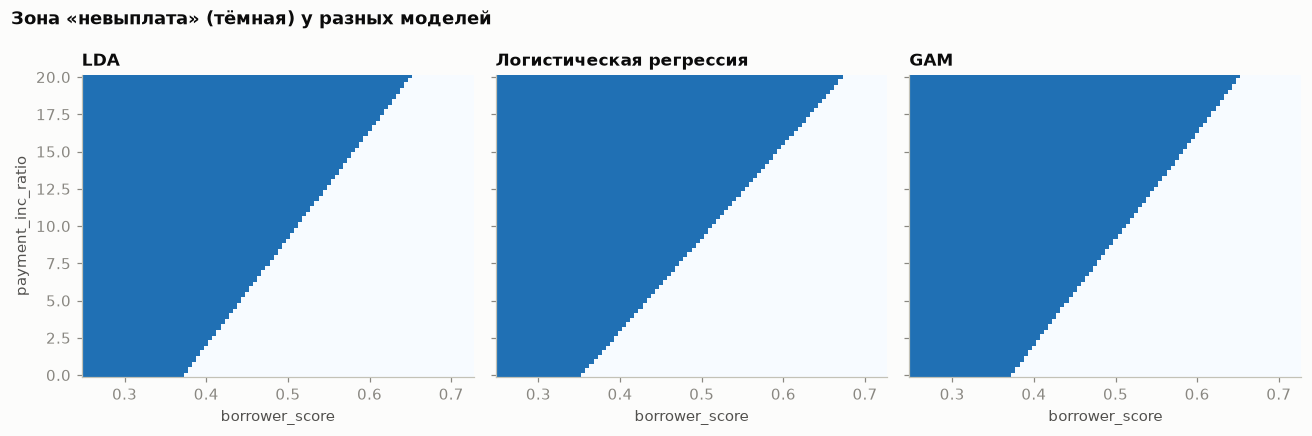

In [30]:
models = {
    "LDA": loan_lda,
    "Логистическая регрессия": logit_reg_2d,
    "GAM": gam,
}

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4), sharex=True, sharey=True)

xvalues = np.arange(0.25, 0.73, 0.005)
yvalues = np.arange(-0.1, 20.1, 0.1)
xx, yy = np.meshgrid(xvalues, yvalues)
grid = pd.DataFrame({
    "borrower_score": xx.ravel(),
    "payment_inc_ratio": yy.ravel(),
})

boundary = {}

for ax, (title, model_) in zip(axes, models.items()):
    if title == "GAM":
        # LogisticGAM даёт вероятность невыплаты; класс «невыплата» — при p > 0.5
        Z = (model_.predict_proba(grid.values) > 0.5).astype(int)
    else:
        Z = np.array([1 if z == "default" else 0 for z in model_.predict(grid)])
    Z = Z.reshape(xx.shape)
    boundary[title] = yvalues[np.argmax(Z > 0, axis=0)]
    boundary[title][Z[-1, :] == 0] = yvalues[-1]

    ax.pcolormesh(xx, yy, Z, cmap="Blues", vmin=0.1, vmax=1.3, shading="auto")
    ax.set_title(title)
    ax.set_xlabel("borrower_score")
    ax.grid(True)
axes[0].set_ylabel("payment_inc_ratio")
fig.suptitle("Зона «невыплата» (тёмная) у разных моделей", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "05_decision_regions")

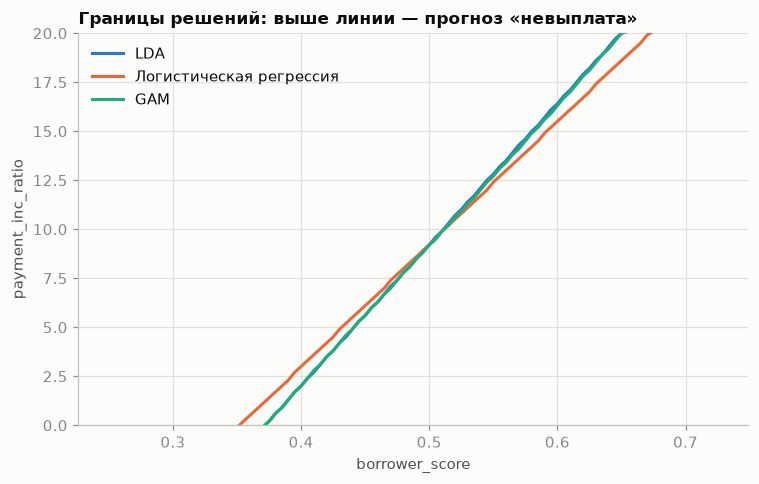

In [31]:
boundary["borrower_score"] = xvalues
boundaries = pd.DataFrame(boundary)

fig, ax = plt.subplots(figsize=(7, 4.5))
boundaries.plot(x="borrower_score", ax=ax)
ax.set_ylabel("payment_inc_ratio")
ax.set_ylim(0, 20)
ax.set_title("Границы решений: выше линии — прогноз «невыплата»")
fig.tight_layout()
save(fig, "06_decision_boundaries")

Все три модели проводят почти одинаковую прямую границу:
- **GAM:** `gridsearch` выбрал максимальный штраф λ = 1000 для обоих признаков, гладкие
  функции практически линейны, и граница совпадает с границей LDA;
- **логистическая регрессия** обучена с регуляризацией по умолчанию (`C = 1`), которая
  сжимает коэффициенты, поэтому её граница немного положе; без регуляризации она
  совпадает с границами LDA и GAM.

Допустимая доля платежа в доходе растёт с баллом кредитоспособности: при балле 0.45
граница проходит около 6%, при 0.5 — около 9%, при 0.6 — около 16%.

## 8. Расширенная модель

Расширенная модель использует признаки `loan_data`, не вошедшие в базовую модель.
Обе модели сравниваются на отложенной выборке.

### 8.1 Новые признаки

Все новые признаки известны в момент подачи заявки.

| Признак | Описание | Преобразование |
|---|---|---|
| `loan_amnt` | сумма ссуды | log₂ (отношение шансов — на удвоение суммы) |
| `term` | срок: 36 или 60 месяцев | флаг `term_60` |
| `annual_inc` | годовой доход | log₂ (отношение шансов — на удвоение дохода) |
| `dti` | долговая нагрузка: платежи по всем долгам / доход, % | без преобразования, на +1 п.п. |
| `revol_util` | использование возобновляемого кредитного лимита, % | на +10 п.п. |
| `grade` | рейтинг ссуды Lending Club (класс и подкласс, закодированы числом 0.2–7) | без преобразования |
| `delinq_2yrs_zero` | 1 — не было просрочек за последние 2 года | без преобразования |
| `open_acc` | число открытых кредитных счетов | на +1 счёт |

Доход и сумма логарифмированы из-за длинного правого хвоста распределения (доход —
до 7 млн). Столбец `status` (`Charged Off` / `Fully Paid`) исключён, так как дублирует
целевую переменную. `borrower_score` в расширенную модель не входит: способ его расчёта
не описан, и для новой заявки его нельзя воспроизвести.

In [32]:
NEW = ["loan_amnt", "term", "annual_inc", "dti", "revol_util", "grade",
       "delinq_2yrs_zero", "open_acc"]
assert loan_data[NEW].notna().all().all() and (loan_data["annual_inc"] > 0).all()
print(loan_data[NEW].describe(include="all").T[["count", "mean", "min", "50%", "max"]].to_string())

                    count          mean     min      50%        max
loan_amnt         45342.0  13154.814521   500.0  11500.0    35000.0
term                45342           NaN     NaN      NaN        NaN
annual_inc        45342.0  68211.696065  2000.0  60000.0  7141778.0
dti               45342.0     16.133731     0.0    16.02      38.86
revol_util        45342.0       56.0518     0.0     58.4      128.1
grade             45342.0      4.599087     0.2      4.8        7.0
delinq_2yrs_zero  45342.0      0.857527     0.0      1.0        1.0
open_acc          45342.0     10.413105     0.0     10.0       76.0


In [33]:
def default_rate(by):
    g = loan_data.groupby(by, observed=True)["outcome"]
    return pd.DataFrame({"ссуд": g.size(), "доля default": g.apply(lambda x: (x == "default").mean())}).round(3)


print("Срок ссуды\n", default_rate("term"), "\n")
print("Рейтинг Lending Club (квинтили)\n", default_rate(pd.qcut(loan_data["grade"], 5)), "\n")
print("Просрочки за 2 года\n", default_rate("delinq_2yrs_zero"))

Срок ссуды
             ссуд  доля default
term                          
36 months  34065         0.449
60 months  11277         0.654 

Рейтинг Lending Club (квинтили)
                ссуд  доля default
grade                            
(0.199, 3.4]  10586         0.662
(3.4, 4.4]     9614         0.555
(4.4, 5.2]     8200         0.504
(5.2, 5.8]     8220         0.423
(5.8, 7.0]     8722         0.313 

Просрочки за 2 года
                    ссуд  доля default
delinq_2yrs_zero                     
0                  6460         0.517
1                 38882         0.497


Новые признаки связаны с риском невыплаты:
- ссуды на 60 месяцев не возвращают заметно чаще, чем на 36;
- доля невыплат монотонно снижается с ростом рейтинга `grade`.

In [34]:
def make_features(data):
    """Признаки расширенной модели: 4 признака базовой модели + 8 новых."""
    out = pd.DataFrame(index=data.index)
    out["payment_inc_ratio"] = data["payment_inc_ratio"]
    out = out.join(pd.get_dummies(data[["purpose_", "home_", "emp_len_"]], prefix="",
                                  prefix_sep="", drop_first=True, dtype=int))
    out["log2_loan_amnt"] = np.log2(data["loan_amnt"])
    out["term_60"] = (data["term"].str.strip() == "60 months").astype(int)
    out["log2_annual_inc"] = np.log2(data["annual_inc"])
    out["dti"] = data["dti"]
    out["revol_util_10"] = data["revol_util"] / 10
    out["grade"] = data["grade"]
    out["delinq_2yrs_zero"] = data["delinq_2yrs_zero"]
    out["open_acc"] = data["open_acc"]
    return out


def make_base_features(data):
    """Признаки базовой модели из разделов 3–5."""
    return pd.get_dummies(
        data[["payment_inc_ratio", "purpose_", "home_", "emp_len_", "borrower_score"]],
        prefix="", prefix_sep="", drop_first=True, dtype=int)

### 8.2 Отложенная выборка и сравнение моделей

`loan_data` разделена на обучающую (70%) и тестовую (30%) части со стратификацией по
исходу. Кросс-валидация (5 фолдов) выполняется на обучающей части, итоговая оценка —
на тестовой.

1. **Базовая модель** — 5 признаков из разделов 3–5.
2. **Расширенная модель** — 4 признака базовой модели (без `borrower_score`) и 8 новых.

In [35]:
SEED = 42
y_def = (loan_data["outcome"] == "default").astype(int)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_train, idx_test = train_test_split(loan_data.index, test_size=0.3, stratify=y_def,
                                       random_state=SEED)
y_train, y_test = y_def.loc[idx_train], y_def.loc[idx_test]

variants = {
    "Базовая: 5 признаков": make_base_features(loan_data),
    "Расширенная: 12 признаков": make_features(loan_data),
}

rows, test_scores = [], {}
for name, feats in variants.items():
    model_ = LogisticRegression(C=1e42, solver="liblinear", max_iter=1000)
    cv_auc = cross_val_score(model_, feats.loc[idx_train], y_train, cv=cv5, scoring="roc_auc")
    model_.fit(feats.loc[idx_train], y_train)
    p_test = model_.predict_proba(feats.loc[idx_test])[:, 1]
    test_scores[name] = p_test
    auc_test = roc_auc_score(y_test, p_test)
    rows.append({"модель": name, "столбцов": feats.shape[1],
                 "CV ROC-AUC (train)": cv_auc.mean(), "± std": cv_auc.std(),
                 "ROC-AUC (test)": auc_test, "Джини (test)": 2 * auc_test - 1})
comparison = pd.DataFrame(rows).round(3)
comparison

,модель,столбцов,CV ROC-AUC (train),± std,ROC-AUC (test),Джини (test)
0,Базовая: 5 признаков,11,0.690,0.007,0.694,0.388
1,Расширенная: 12 признаков,18,0.692,0.006,0.701,0.401


**Результаты:**
- на тесте расширенная модель немного лучше: ROC-AUC 0.701 против 0.694 (Джини 0.40
  против 0.39);
- на кросс-валидации разница 0.002 (0.692 против 0.690) меньше разброса между фолдами
  (±0.006–0.007): по качеству ранжирования модели практически равны;
- результаты на тесте и кросс-валидации согласуются, признаков переобучения нет.

Преимущество расширенной модели — независимость от готового балла: она использует только
данные заявки, и каждый фактор риска интерпретируем.

### 8.3 Отношения шансов расширенной модели

Расширенная модель, обученная в statsmodels на обучающей части: доверительные интервалы
и p-значения.

In [36]:
X_ext = make_features(loan_data)
ext_glm = sm.GLM(y_train, X_ext.loc[idx_train].assign(const=1),
                 family=sm.families.Binomial()).fit()
ci = np.exp(ext_glm.conf_int())
ext_odds = pd.DataFrame({
    "odds_ratio": np.exp(ext_glm.params), "ci_low": ci[0], "ci_high": ci[1],
    "p_value": ext_glm.pvalues,
}).drop(index="const")
ext_odds.index = ext_odds.index.str.strip()
ext_odds = ext_odds.sort_values("odds_ratio")
ext_odds.style.format({"odds_ratio": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}",
                       "p_value": "{:.1e}"})

,odds_ratio,ci_low,ci_high,p_value
> 1 Year,0.707,0.625,0.801,4.6e-08
grade,0.818,0.802,0.835,8.9e-87
log2_annual_inc,0.831,0.771,0.897,1.7e-06
log2_loan_amnt,0.878,0.819,0.941,2.5e-04
delinq_2yrs_zero,0.928,0.867,0.993,3.1e-02
open_acc,1.009,1.003,1.015,3.7e-03
dti,1.017,1.014,1.021,4.0e-21
OWN,1.018,0.930,1.113,7.0e-01
payment_inc_ratio,1.071,1.056,1.087,6.7e-20
revol_util_10,1.079,1.068,1.091,8.0e-44


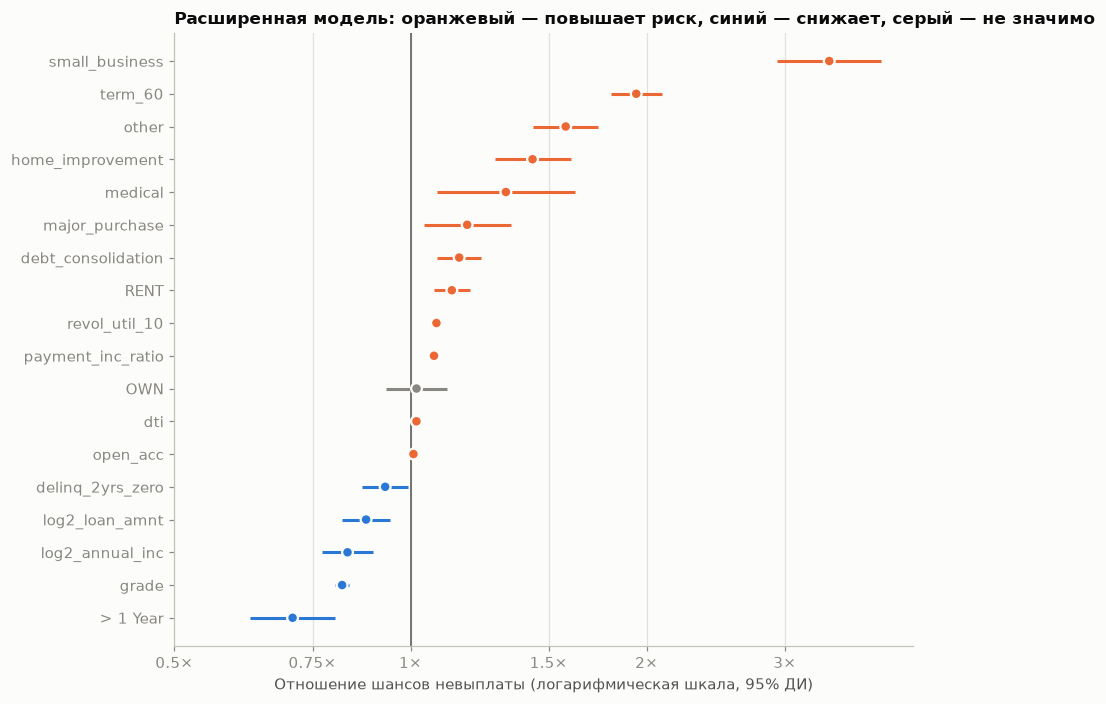

In [37]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ypos = np.arange(len(ext_odds))
sig = ext_odds["p_value"] < 0.05
colors = np.where(~sig, PAL["muted"], np.where(ext_odds["odds_ratio"] > 1, PAL["orange"], PAL["blue"]))
ax.hlines(ypos, ext_odds["ci_low"], ext_odds["ci_high"], color=colors, lw=2)
ax.scatter(ext_odds["odds_ratio"], ypos, color=colors, s=50, zorder=3,
           edgecolor=PAL["surface"], lw=1.5)
ax.axvline(1, color=PAL["ink2"], lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3])
ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_yticks(ypos, ext_odds.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Отношение шансов невыплаты (логарифмическая шкала, 95% ДИ)")
ax.set_title("Расширенная модель: оранжевый — повышает риск, синий — снижает, серый — не значимо")
fig.tight_layout()
save(fig, "07_odds_ratios_extended")

**Новые признаки:**
- **срок 60 месяцев** — самый сильный из новых факторов: шансы невыплаты почти в 2 раза
  выше, чем при сроке 36 месяцев (OR ≈ 1.94);
- **рейтинг `grade`**: каждая единица снижает шансы невыплаты примерно на 18% (OR ≈ 0.82);
  разница между крайними значениями (0.2 и 7.0) — примерно в 4 раза;
- **использование кредитного лимита**: +10 п.п. `revol_util` — шансы ×1.08;
- **долговая нагрузка**: +1 п.п. `dti` — шансы ×1.017 (+10 п.п. — ×1.18);
- **доход**: удвоение дохода снижает шансы невыплаты в ~0.83 раза;
- **отсутствие просрочек** за 2 года и **число открытых счетов** значимы, но влияют слабо;
- **сумма ссуды**: OR < 1 (×0.88 на удвоение). Сумма, доход, срок и доля платежа в доходе
  жёстко связаны (платёж определяется суммой и сроком), поэтому коэффициент отражает
  эффект при фиксированных остальных признаках, а не самостоятельную зависимость.

Признаки базовой модели сохранили направление влияния: ссуды малому бизнесу остаются
самыми рискованными (OR ≈ 3.4), аренда жилья повышает риск, стаж больше года снижает.

### 8.4 ROC-кривые на тестовой выборке

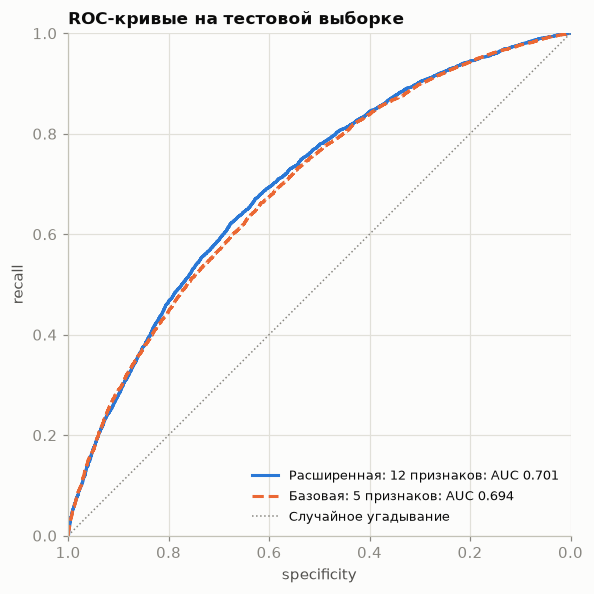

In [38]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for name, color, ls in [
    ("Расширенная: 12 признаков", PAL["blue"], "-"),
    ("Базовая: 5 признаков", PAL["orange"], "--"),
]:
    fpr_, tpr_, _ = roc_curve(y_test, test_scores[name])
    ax.plot(1 - fpr_, tpr_, color=color, ls=ls,
            label=f"{name}: AUC {roc_auc_score(y_test, test_scores[name]):.3f}")
ax.plot((1, 0), (0, 1), color=PAL["muted"], lw=1, ls=":", label="Случайное угадывание")
ax.set_xlim(1, 0)
ax.set_ylim(0, 1)
ax.set_xlabel("specificity")
ax.set_ylabel("recall")
ax.set_title("ROC-кривые на тестовой выборке")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
save(fig, "08_roc_extended")

### 8.5 Метрики на тесте (порог 0.5)

In [39]:
def test_metrics(p):
    pred_ = np.where(p >= 0.5, "default", "paid off")
    true_ = np.where(y_test == 1, "default", "paid off")
    cm_ = confusion_matrix(true_, pred_, labels=["default", "paid off"])
    auc_ = roc_auc_score(y_test, p)
    return {"accuracy": accuracy_score(true_, pred_),
            "precision": cm_[0, 0] / cm_[:, 0].sum(),
            "recall": cm_[0, 0] / cm_[0, :].sum(),
            "specificity": cm_[1, 1] / cm_[1, :].sum(),
            "ROC-AUC": auc_, "Джини": 2 * auc_ - 1}


p_ext = test_scores["Расширенная: 12 признаков"]
classification_summary(np.where(y_test == 1, "default", "paid off"),
                       np.where(p_ext >= 0.5, "default", "paid off"),
                       class_names=["default", "paid off"])
pd.DataFrame({name: test_metrics(p) for name, p in test_scores.items()}).round(3)

Матрица ошибок (accuracy = 0.6485)

                прогноз: default  прогноз: paid off
факт: default               4246               2555
факт: paid off              2227               4575


,Базовая: 5 признаков,Расширенная: 12 признаков
accuracy,0.637,0.648
precision,0.639,0.656
recall,0.632,0.624
specificity,0.643,0.673
ROC-AUC,0.694,0.701
Джини,0.388,0.401


## 9. Итоги

**Главный результат.** На отложенной выборке расширенная модель (12 признаков заявки)
даёт **ROC-AUC 0.701 (Джини 0.40)**, базовая (5 признаков, включая `borrower_score`) —
0.694 (Джини 0.39). По качеству ранжирования модели практически равны; расширенная
модель не зависит от готового балла и описывает риск через характеристики заёмщика
и ссуды.

| Модель | CV ROC-AUC | ROC-AUC (test) | Джини | Accuracy | Precision | Recall | Specificity |
|---|---|---|---|---|---|---|---|
| Базовая: 5 признаков | 0.690 | 0.694 | 0.39 | 63.7% | 63.9% | 63.2% | 64.3% |
| **Расширенная: 12 признаков** | 0.692 | **0.701** | **0.40** | 64.8% | 65.6% | 62.4% | 67.3% |

Метрики классификации — на тестовой части при пороге 0.5.

**Факторы риска** (расширенная модель, отношение шансов невыплаты):
- ссуда малому бизнесу — ×3.4 к ссудам на кредитную карту;
- срок 60 месяцев — ×1.9 к сроку 36 месяцев;
- рейтинг Lending Club: каждая единица снижает шансы примерно на 18%;
- нагрузка: доля платежа в доходе (×1.07 на +1 п.п.), использование кредитного лимита
  (×1.08 на +10 п.п.), долговая нагрузка `dti` (×1.18 на +10 п.п.);
- аренда жилья (×1.13) повышает риск; стаж больше года (×0.71) и удвоение дохода (×0.83)
  снижают.

**Другие результаты:**
- при естественной доле невыплат 19% модель без коррекции отмечает невыплату только у 1%
  ссуд; перевзвешивание поднимает долю прогнозов до 62%, SMOTE и ADASYN — до 27–29%;
- на двух признаках логистическая регрессия, LDA и GAM (`LogisticGAM`) проводят почти
  одинаковую прямую границу решений; GAM выбрала максимальное сглаживание.

**Ограничения**
- Модели разделов 3–7 оценены на обучающих данных; на отложенной выборке проверены
  только модели раздела 8.
- Модели обучены на сбалансированной выборке (50% невыплат), поэтому вероятности завышены
  относительно фактической доли 19% и требуют калибровки.
- В данных нет дат выдачи, поэтому проверка на более позднем периоде (out-of-time)
  невозможна; её можно выполнить на полной версии данных Lending Club.
- Порог отсечения следует выбирать по стоимости ошибок: потерям на одной невыплате
  и упущенному доходу от одного ошибочного отказа.